Loading data...
Allen-Cahn variables: ['T', 'X', 'x_flat', 't_flat', 'u_pred', 'u_exact', 'pde_residual_grid', 'iter_history', 'loss_history', 'error_history']
Burgers variables: ['T', 'X', 'u_pred', 'u_exact', 'pde_residual_grid', 'iter_history', 'loss_history', 'error_history']
Helmholtz variables: ['X', 'Y', 'u_pred', 'u_exact', 'pde_residual_grid', 'iter_history', 'loss_history', 'error_history', 'pointwise_error']
KdV variables: ['t', 'x', 'T', 'X', 'u_pred', 'u_exact', 'pde_residual_grid', 'iter_history', 'loss_history', 'error_history']
Allen-Cahn shapes - T: (512, 501), u_pred: (512, 501)
Burgers shapes - T: (2001, 1001), u_pred: (2001, 1001)
Helmholtz shapes - X: (256, 256), u_pred: (256, 256)
KdV shapes - T: (201, 101), u_pred: (201, 101), residual: (201, 101)

✓ Figure saved as 'pde_comparison_4cases.png'


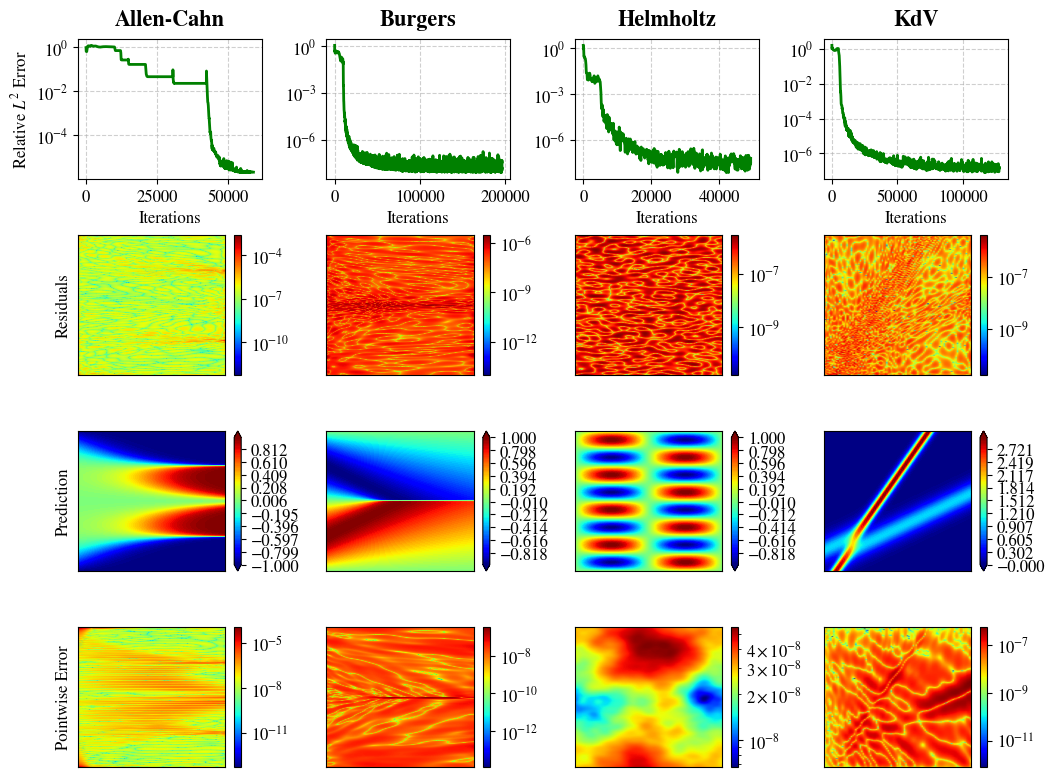


SUMMARY STATISTICS

Allen-Cahn:
  Final Relative L2:     2.177636e-06
  Min Relative L2:       2.067266e-06
  Max Pointwise Error:   1.229232e-04
  Mean Pointwise Error:  1.713053e-07
  Max Residual:          2.477548e-03

Burgers:
  Final Relative L2:     3.792732e-08
  Min Relative L2:       7.876904e-09
  Max Pointwise Error:   3.286472e-07
  Mean Pointwise Error:  1.711547e-08
  Max Residual:          2.915849e-06

Helmholtz:
  Final Relative L2:     6.228301e-08
  Min Relative L2:       7.254935e-09
  Max Pointwise Error:   5.545384e-08
  Mean Pointwise Error:  2.904005e-08
  Max Residual:          2.745412e-06

KdV:
  Final Relative L2:     1.536840e-07
  Min Relative L2:       7.922833e-08
  Max Pointwise Error:   5.577998e-07
  Mean Pointwise Error:  6.370773e-08
  Max Residual:          4.087168e-06



In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import colors

# Set font and style parameters
mpl.rcParams['mathtext.fontset'] = 'stix'
mpl.rcParams['font.family'] = 'STIXGeneral'
mpl.rcParams['font.size'] = 12
mpl.rcParams['figure.dpi'] = 100

# ## Load Data from All Four Cases
print("Loading data...")

# Allen-Cahn
allen_cahn_path = '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/AllenCahn_Periodic_X2CosPiX/2025_12_05_1208_human/complete_results.npz'
allen_cahn_data = np.load(allen_cahn_path)
print(f"Allen-Cahn variables: {list(allen_cahn_data.keys())}")

# Burgers
burgers_path = '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/Burgers_Periodic_SinPiX/2025_12_05_1236_human/solution_data.npz'
burgers_data = np.load(burgers_path)
print(f"Burgers variables: {list(burgers_data.keys())}")

# Helmholtz
helmholtz_path = '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/Helmholtz_Periodic_SinPiA1SinPiA2/2025_12_05_1421/validation_data.npz'
helmholtz_data = np.load(helmholtz_path)
print(f"Helmholtz variables: {list(helmholtz_data.keys())}")

# KdV
kdv_path = '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/KdV_Mixed_DerivedIC/2026_01_10_2026_human/Kdv.npz'
kdv_data = np.load(kdv_path)
print(f"KdV variables: {list(kdv_data.keys())}")

# ## Extract Allen-Cahn Data
ac_T = allen_cahn_data['T']
ac_X = allen_cahn_data['X']
ac_u_pred = allen_cahn_data['u_pred']
ac_u_exact = allen_cahn_data['u_exact']
ac_residual = allen_cahn_data['pde_residual_grid']
ac_iter = allen_cahn_data['iter_history']
ac_loss = allen_cahn_data['loss_history']
ac_errors = allen_cahn_data['error_history']
ac_pointwise_error = np.abs(ac_u_exact - ac_u_pred)

print(f"Allen-Cahn shapes - T: {ac_T.shape}, u_pred: {ac_u_pred.shape}")

# ## Extract Burgers Data
b_T = burgers_data['T']
b_X = burgers_data['X']
b_u_pred = burgers_data['u_pred']
b_u_exact = burgers_data['u_exact']
b_residual = burgers_data['pde_residual_grid']
b_iter = burgers_data['iter_history']
b_loss = burgers_data['loss_history']
b_errors = burgers_data['error_history']
b_pointwise_error = np.abs(b_u_exact - b_u_pred)

print(f"Burgers shapes - T: {b_T.shape}, u_pred: {b_u_pred.shape}")

# ## Extract Helmholtz Data
h_X = helmholtz_data['X']
h_Y = helmholtz_data['Y']
h_U_pred = helmholtz_data['u_pred']
h_U_exact = helmholtz_data['u_exact']
h_residual = helmholtz_data['pde_residual_grid']
h_iter = helmholtz_data['iter_history']
h_loss = helmholtz_data['loss_history']
h_errors = helmholtz_data['error_history']
h_pointwise_error = helmholtz_data['pointwise_error']

print(f"Helmholtz shapes - X: {h_X.shape}, u_pred: {h_U_pred.shape}")

# ## Extract KdV Data
kdv_T = kdv_data['T']
kdv_X = kdv_data['X']
kdv_u_pred = kdv_data['u_pred']
kdv_u_exact = kdv_data['u_exact']
kdv_residual = kdv_data['pde_residual_grid'].T
kdv_iter = kdv_data['iter_history']
kdv_loss = kdv_data['loss_history']
kdv_errors = kdv_data['error_history']
kdv_pointwise_error = np.abs(kdv_u_exact - kdv_u_pred)

print(f"KdV shapes - T: {kdv_T.shape}, u_pred: {kdv_u_pred.shape}, residual: {kdv_residual.shape}")

# Check if transpose is needed for KdV
if kdv_T.shape != kdv_u_pred.shape:
    print(f"WARNING: KdV mesh shape mismatch. Transposing data...")
    kdv_u_pred = kdv_u_pred.T
    kdv_u_exact = kdv_u_exact.T
    kdv_residual = kdv_residual.T
    kdv_pointwise_error = kdv_pointwise_error.T
    print(f"After transpose - u_pred: {kdv_u_pred.shape}, residual: {kdv_residual.shape}")

# ## Create Combined 4×4 Visualization
fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(4, 4, hspace=0.4, wspace=0.35, top=0.96, bottom=0.05)

# Define consistent styling
error_color = 'green'

# Row labels for the leftmost column
row_labels = ['Relative $L^2$ Error', 'Residuals', 'Prediction', 'Pointwise Error']

# ============================================================================
# ROW 1: RELATIVE ERROR HISTORY (LOG SCALE)
# ============================================================================

# Allen-Cahn (Column 1)
ax_ac_err = fig.add_subplot(gs[0, 0])
ax_ac_err.plot(ac_iter, ac_errors, color=error_color, linewidth=2)
ax_ac_err.set_yscale('log')
ax_ac_err.set_title('Allen-Cahn', fontsize=16, pad=10)
ax_ac_err.set_xlabel('Iterations')
ax_ac_err.set_ylabel(row_labels[0])
ax_ac_err.grid(True, which="both", ls="--", alpha=0.6)

# Burgers (Column 2)
ax_b_err = fig.add_subplot(gs[0, 1])
ax_b_err.plot(b_iter, b_errors, color=error_color, linewidth=2)
ax_b_err.set_yscale('log')
ax_b_err.set_title('Burgers', fontsize=16, pad=10)
ax_b_err.set_xlabel('Iterations')
ax_b_err.set_ylabel('')
ax_b_err.grid(True, which="both", ls="--", alpha=0.6)

# Helmholtz (Column 3)
ax_h_err = fig.add_subplot(gs[0, 2])
ax_h_err.plot(h_iter, h_errors, color=error_color, linewidth=2)
ax_h_err.set_yscale('log')
ax_h_err.set_title('Helmholtz', fontsize=16, pad=10)
ax_h_err.set_xlabel('Iterations')
ax_h_err.set_ylabel('')
ax_h_err.grid(True, which="both", ls="--", alpha=0.6)

# KdV (Column 4)
ax_kdv_err = fig.add_subplot(gs[0, 3])
ax_kdv_err.plot(kdv_iter, kdv_errors, color=error_color, linewidth=2)
ax_kdv_err.set_yscale('log')
ax_kdv_err.set_title('KdV', fontsize=16, pad=10)
ax_kdv_err.set_xlabel('Iterations')
ax_kdv_err.set_ylabel('')
ax_kdv_err.grid(True, which="both", ls="--", alpha=0.6)

# ============================================================================
# ROW 2: PDE RESIDUALS (LOG SCALE)
# ============================================================================

# Allen-Cahn (Column 1)
ax_ac_res = fig.add_subplot(gs[1, 0])
ac_res_safe = np.maximum(np.abs(ac_residual), 1e-16)
ac_res_norm = colors.LogNorm(vmin=ac_res_safe.min(), vmax=ac_res_safe.max())
mesh_ac_res = ax_ac_res.pcolormesh(ac_T, ac_X, ac_res_safe, cmap='jet', 
                                    norm=ac_res_norm, shading='gouraud')
cbar_ac_res = fig.colorbar(mesh_ac_res, ax=ax_ac_res)
ax_ac_res.set_xlabel('')
ax_ac_res.set_ylabel(row_labels[1])
ax_ac_res.set_xticks([])
ax_ac_res.set_yticks([])

# Burgers (Column 2)
ax_b_res = fig.add_subplot(gs[1, 1])
b_res_safe = np.maximum(np.abs(b_residual), 1e-16)
b_res_norm = colors.LogNorm(vmin=b_res_safe.min(), vmax=b_res_safe.max())
mesh_b_res = ax_b_res.pcolormesh(b_T, b_X, b_res_safe, cmap='jet', 
                                  norm=b_res_norm, shading='gouraud')
cbar_b_res = fig.colorbar(mesh_b_res, ax=ax_b_res)
ax_b_res.set_xlabel('')
ax_b_res.set_ylabel('')
ax_b_res.set_xticks([])
ax_b_res.set_yticks([])

# Helmholtz (Column 3)
ax_h_res = fig.add_subplot(gs[1, 2])
h_res_safe = np.maximum(np.abs(h_residual), 1e-16)
h_res_norm = colors.LogNorm(vmin=h_res_safe.min(), vmax=h_res_safe.max())
mesh_h_res = ax_h_res.pcolormesh(h_X, h_Y, h_res_safe, cmap='jet', 
                                  norm=h_res_norm, shading='gouraud')
cbar_h_res = fig.colorbar(mesh_h_res, ax=ax_h_res)
ax_h_res.set_xlabel('')
ax_h_res.set_ylabel('')
ax_h_res.set_xticks([])
ax_h_res.set_yticks([])

# KdV (Column 4)
ax_kdv_res = fig.add_subplot(gs[1, 3])
kdv_res_safe = np.maximum(np.abs(kdv_residual), 1e-16)
kdv_res_norm = colors.LogNorm(vmin=kdv_res_safe.min(), vmax=kdv_res_safe.max())
mesh_kdv_res = ax_kdv_res.pcolormesh(kdv_T, kdv_X, kdv_res_safe, cmap='jet', 
                                      norm=kdv_res_norm, shading='gouraud')
cbar_kdv_res = fig.colorbar(mesh_kdv_res, ax=ax_kdv_res)
ax_kdv_res.set_xlabel('')
ax_kdv_res.set_ylabel('')
ax_kdv_res.set_xticks([])
ax_kdv_res.set_yticks([])

# ============================================================================
# ROW 3: PREDICTIONS
# ============================================================================

# Allen-Cahn (Column 1)
ax_ac_pred = fig.add_subplot(gs[2, 0])
ac_vmin, ac_vmax = ac_u_pred.min(), ac_u_pred.max()
ac_levels = np.linspace(ac_vmin, ac_vmax, 100)
contour_ac_pred = ax_ac_pred.contourf(ac_T, ac_X, ac_u_pred, cmap='jet', 
                                       levels=ac_levels, extend='both')
cbar_ac_pred = fig.colorbar(contour_ac_pred, ax=ax_ac_pred)
ax_ac_pred.set_xlabel('')
ax_ac_pred.set_ylabel(row_labels[2])
ax_ac_pred.set_xticks([])
ax_ac_pred.set_yticks([])

# Burgers (Column 2)
ax_b_pred = fig.add_subplot(gs[2, 1])
b_vmin, b_vmax = b_u_pred.min(), b_u_pred.max()
b_levels = np.linspace(b_vmin, b_vmax, 100)
contour_b_pred = ax_b_pred.contourf(b_T, b_X, b_u_pred, cmap='jet', 
                                     levels=b_levels, extend='both')
cbar_b_pred = fig.colorbar(contour_b_pred, ax=ax_b_pred)
ax_b_pred.set_xlabel('')
ax_b_pred.set_ylabel('')
ax_b_pred.set_xticks([])
ax_b_pred.set_yticks([])

# Helmholtz (Column 3)
ax_h_pred = fig.add_subplot(gs[2, 2])
h_vmin, h_vmax = h_U_pred.min(), h_U_pred.max()
h_levels = np.linspace(h_vmin, h_vmax, 100)
contour_h_pred = ax_h_pred.contourf(h_X, h_Y, h_U_pred, cmap='jet', 
                                     levels=h_levels, extend='both')
cbar_h_pred = fig.colorbar(contour_h_pred, ax=ax_h_pred)
ax_h_pred.set_xlabel('')
ax_h_pred.set_ylabel('')
ax_h_pred.set_xticks([])
ax_h_pred.set_yticks([])

# KdV (Column 4)
ax_kdv_pred = fig.add_subplot(gs[2, 3])
kdv_vmin, kdv_vmax = kdv_u_pred.min(), kdv_u_pred.max()
kdv_levels = np.linspace(kdv_vmin, kdv_vmax, 100)
contour_kdv_pred = ax_kdv_pred.contourf(kdv_T, kdv_X, kdv_u_pred, cmap='jet', 
                                         levels=kdv_levels, extend='both')
cbar_kdv_pred = fig.colorbar(contour_kdv_pred, ax=ax_kdv_pred)
ax_kdv_pred.set_xlabel('')
ax_kdv_pred.set_ylabel('')
ax_kdv_pred.set_xticks([])
ax_kdv_pred.set_yticks([])

# ============================================================================
# ROW 4: POINTWISE ERROR (LOG SCALE)
# ============================================================================

# Allen-Cahn (Column 1)
ax_ac_perr = fig.add_subplot(gs[3, 0])
ac_perr_safe = np.maximum(ac_pointwise_error, 1e-16)
ac_perr_norm = colors.LogNorm(vmin=ac_perr_safe.min(), vmax=ac_perr_safe.max())
mesh_ac_perr = ax_ac_perr.pcolormesh(ac_T, ac_X, ac_perr_safe, cmap='jet', 
                                      norm=ac_perr_norm, shading='gouraud')
cbar_ac_perr = fig.colorbar(mesh_ac_perr, ax=ax_ac_perr)
ax_ac_perr.set_xlabel('')
ax_ac_perr.set_ylabel(row_labels[3])
ax_ac_perr.set_xticks([])
ax_ac_perr.set_yticks([])

# Burgers (Column 2)
ax_b_perr = fig.add_subplot(gs[3, 1])
b_perr_safe = np.maximum(b_pointwise_error, 1e-16)
b_perr_norm = colors.LogNorm(vmin=b_perr_safe.min(), vmax=b_perr_safe.max())
mesh_b_perr = ax_b_perr.pcolormesh(b_T, b_X, b_perr_safe, cmap='jet', 
                                    norm=b_perr_norm, shading='gouraud')
cbar_b_perr = fig.colorbar(mesh_b_perr, ax=ax_b_perr)
ax_b_perr.set_xlabel('')
ax_b_perr.set_ylabel('')
ax_b_perr.set_xticks([])
ax_b_perr.set_yticks([])

# Helmholtz (Column 3)
ax_h_perr = fig.add_subplot(gs[3, 2])
h_perr_safe = np.maximum(np.abs(h_pointwise_error), 1e-16)
h_perr_norm = colors.LogNorm(vmin=h_perr_safe.min(), vmax=h_perr_safe.max())
mesh_h_perr = ax_h_perr.pcolormesh(h_X, h_Y, h_perr_safe, cmap='jet', 
                                    norm=h_perr_norm, shading='gouraud')
cbar_h_perr = fig.colorbar(mesh_h_perr, ax=ax_h_perr)
ax_h_perr.set_xlabel('')
ax_h_perr.set_ylabel('')
ax_h_perr.set_xticks([])
ax_h_perr.set_yticks([])

# KdV (Column 4)
ax_kdv_perr = fig.add_subplot(gs[3, 3])
kdv_perr_safe = np.maximum(kdv_pointwise_error, 1e-16)
kdv_perr_norm = colors.LogNorm(vmin=kdv_perr_safe.min(), vmax=kdv_perr_safe.max())
mesh_kdv_perr = ax_kdv_perr.pcolormesh(kdv_T, kdv_X, kdv_perr_safe, cmap='jet', 
                                        norm=kdv_perr_norm, shading='gouraud')
cbar_kdv_perr = fig.colorbar(mesh_kdv_perr, ax=ax_kdv_perr)
ax_kdv_perr.set_xlabel('')
ax_kdv_perr.set_ylabel('')
ax_kdv_perr.set_xticks([])
ax_kdv_perr.set_yticks([])

# ============================================================================
# Final Layout and Save
# ============================================================================

plt.savefig('pde_comparison_4cases.png', dpi=300, bbox_inches='tight')
print("\n✓ Figure saved as 'pde_comparison_4cases.png'")

plt.show()

# ============================================================================
# Print Summary Statistics
# ============================================================================

print("\n" + "="*70)
print("SUMMARY STATISTICS")
print("="*70)

print(f"\nAllen-Cahn:")
print(f"  Final Relative L2:     {ac_errors[-1]:.6e}")
print(f"  Min Relative L2:       {ac_errors.min():.6e}")
print(f"  Max Pointwise Error:   {ac_pointwise_error.max():.6e}")
print(f"  Mean Pointwise Error:  {ac_pointwise_error.mean():.6e}")
print(f"  Max Residual:          {np.abs(ac_residual).max():.6e}")

print(f"\nBurgers:")
print(f"  Final Relative L2:     {b_errors[-1]:.6e}")
print(f"  Min Relative L2:       {b_errors.min():.6e}")
print(f"  Max Pointwise Error:   {b_pointwise_error.max():.6e}")
print(f"  Mean Pointwise Error:  {b_pointwise_error.mean():.6e}")
print(f"  Max Residual:          {np.abs(b_residual).max():.6e}")

print(f"\nHelmholtz:")
print(f"  Final Relative L2:     {h_errors[-1]:.6e}")
print(f"  Min Relative L2:       {h_errors.min():.6e}")
print(f"  Max Pointwise Error:   {h_pointwise_error.max():.6e}")
print(f"  Mean Pointwise Error:  {h_pointwise_error.mean():.6e}")
print(f"  Max Residual:          {np.abs(h_residual).max():.6e}")

print(f"\nKdV:")
print(f"  Final Relative L2:     {kdv_errors[-1]:.6e}")
print(f"  Min Relative L2:       {kdv_errors.min():.6e}")
print(f"  Max Pointwise Error:   {kdv_pointwise_error.max():.6e}")
print(f"  Mean Pointwise Error:  {kdv_pointwise_error.mean():.6e}")
print(f"  Max Residual:          {np.abs(kdv_residual).max():.6e}")

print("\n" + "="*70)

Loading data...
Allen-Cahn variables: ['T', 'X', 'x_flat', 't_flat', 'u_pred', 'u_exact', 'pde_residual_grid', 'iter_history', 'loss_history', 'error_history']
Burgers variables: ['T', 'X', 'u_pred', 'u_exact', 'pde_residual_grid', 'iter_history', 'loss_history', 'error_history']
Helmholtz variables: ['X', 'Y', 'u_pred', 'u_exact', 'pde_residual_grid', 'iter_history', 'loss_history', 'error_history', 'pointwise_error']
KdV variables: ['t', 'x', 'T', 'X', 'u_pred', 'u_exact', 'pde_residual_grid', 'iter_history', 'loss_history', 'error_history']
Allen-Cahn shapes - T: (512, 501), u_pred: (512, 501)
Burgers shapes - T: (2001, 1001), u_pred: (2001, 1001)
Helmholtz shapes - X: (256, 256), u_pred: (256, 256)
KdV shapes - T: (201, 101), u_pred: (201, 101), residual: (201, 101)

✓ Figure saved as 'pde_comparison_4cases.png'


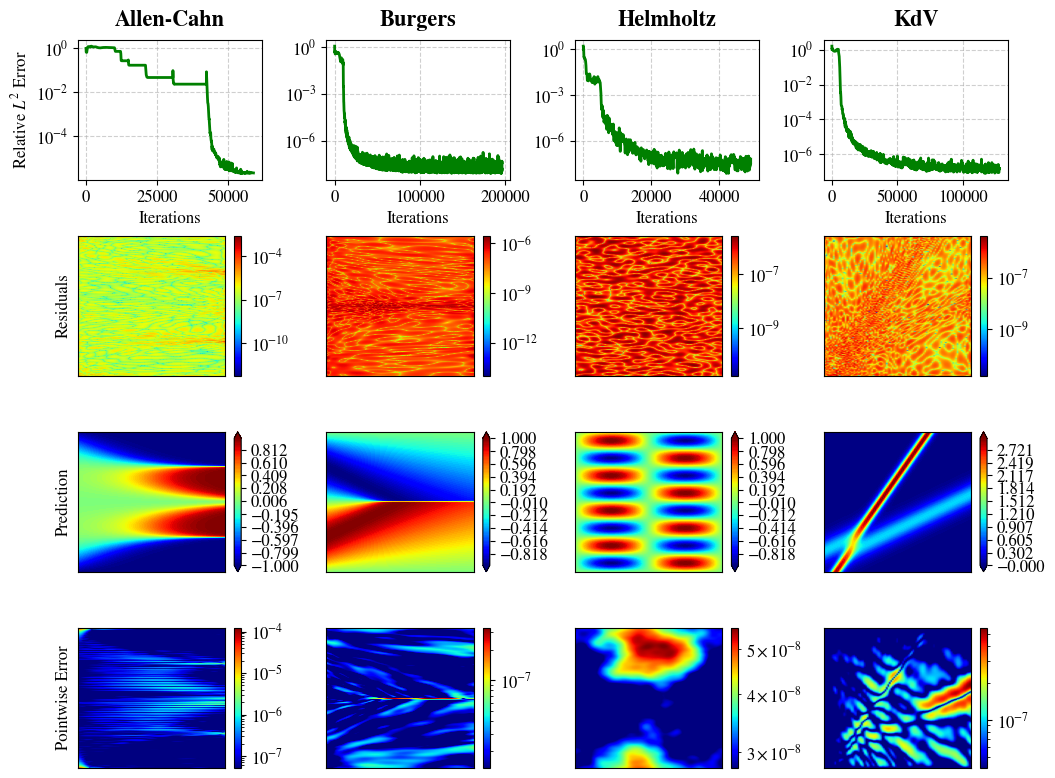


SUMMARY STATISTICS

Allen-Cahn:
  Final Relative L2:     2.177636e-06
  Min Relative L2:       2.067266e-06
  Max Pointwise Error:   1.229232e-04
  Mean Pointwise Error:  1.713053e-07
  Max Residual:          2.477548e-03

Burgers:
  Final Relative L2:     3.792732e-08
  Min Relative L2:       7.876904e-09
  Max Pointwise Error:   3.286472e-07
  Mean Pointwise Error:  1.711547e-08
  Max Residual:          2.915849e-06

Helmholtz:
  Final Relative L2:     6.228301e-08
  Min Relative L2:       7.254935e-09
  Max Pointwise Error:   5.545384e-08
  Mean Pointwise Error:  2.904005e-08
  Max Residual:          2.745412e-06

KdV:
  Final Relative L2:     1.536840e-07
  Min Relative L2:       7.922833e-08
  Max Pointwise Error:   5.577998e-07
  Mean Pointwise Error:  6.370773e-08
  Max Residual:          4.087168e-06



In [6]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import colors

# Set font and style parameters
mpl.rcParams['mathtext.fontset'] = 'stix'
mpl.rcParams['font.family'] = 'STIXGeneral'
mpl.rcParams['font.size'] = 12
mpl.rcParams['figure.dpi'] = 100

# ## Load Data from All Four Cases
print("Loading data...")

# Allen-Cahn
allen_cahn_path = '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/AllenCahn_Periodic_X2CosPiX/2025_12_05_1208_human/complete_results.npz'
allen_cahn_data = np.load(allen_cahn_path)
print(f"Allen-Cahn variables: {list(allen_cahn_data.keys())}")

# Burgers
burgers_path = '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/Burgers_Periodic_SinPiX/2025_12_05_1236_human/solution_data.npz'
burgers_data = np.load(burgers_path)
print(f"Burgers variables: {list(burgers_data.keys())}")

# Helmholtz
helmholtz_path = '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/Helmholtz_Periodic_SinPiA1SinPiA2/2025_12_05_1421/validation_data.npz'
helmholtz_data = np.load(helmholtz_path)
print(f"Helmholtz variables: {list(helmholtz_data.keys())}")

# KdV
kdv_path = '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/KdV_Mixed_DerivedIC/2026_01_10_2026_human/Kdv.npz'
kdv_data = np.load(kdv_path)
print(f"KdV variables: {list(kdv_data.keys())}")


# Poisson 
Poisson_path= '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/Poisson_Dirichlet_Sin4pixSin4piy/2026_01_10_2319_plots/Poisson.npz'

# ## Extract Allen-Cahn Data
ac_T = allen_cahn_data['T']
ac_X = allen_cahn_data['X']
ac_u_pred = allen_cahn_data['u_pred']
ac_u_exact = allen_cahn_data['u_exact']
ac_residual = allen_cahn_data['pde_residual_grid']
ac_iter = allen_cahn_data['iter_history']
ac_loss = allen_cahn_data['loss_history']
ac_errors = allen_cahn_data['error_history']
ac_pointwise_error = np.abs(ac_u_exact - ac_u_pred)

print(f"Allen-Cahn shapes - T: {ac_T.shape}, u_pred: {ac_u_pred.shape}")

# ## Extract Burgers Data
b_T = burgers_data['T']
b_X = burgers_data['X']
b_u_pred = burgers_data['u_pred']
b_u_exact = burgers_data['u_exact']
b_residual = burgers_data['pde_residual_grid']
b_iter = burgers_data['iter_history']
b_loss = burgers_data['loss_history']
b_errors = burgers_data['error_history']
b_pointwise_error = np.abs(b_u_exact - b_u_pred)

print(f"Burgers shapes - T: {b_T.shape}, u_pred: {b_u_pred.shape}")

# ## Extract Helmholtz Data
h_X = helmholtz_data['X']
h_Y = helmholtz_data['Y']
h_U_pred = helmholtz_data['u_pred']
h_U_exact = helmholtz_data['u_exact']
h_residual = helmholtz_data['pde_residual_grid']
h_iter = helmholtz_data['iter_history']
h_loss = helmholtz_data['loss_history']
h_errors = helmholtz_data['error_history']
h_pointwise_error = helmholtz_data['pointwise_error']

print(f"Helmholtz shapes - X: {h_X.shape}, u_pred: {h_U_pred.shape}")

# ## Extract KdV Data
kdv_T = kdv_data['T']
kdv_X = kdv_data['X']
kdv_u_pred = kdv_data['u_pred']
kdv_u_exact = kdv_data['u_exact']
kdv_residual = kdv_data['pde_residual_grid'].T
kdv_iter = kdv_data['iter_history']
kdv_loss = kdv_data['loss_history']
kdv_errors = kdv_data['error_history']
kdv_pointwise_error = np.abs(kdv_u_exact - kdv_u_pred)

print(f"KdV shapes - T: {kdv_T.shape}, u_pred: {kdv_u_pred.shape}, residual: {kdv_residual.shape}")

# Check if transpose is needed for KdV
if kdv_T.shape != kdv_u_pred.shape:
    print(f"WARNING: KdV mesh shape mismatch. Transposing data...")
    kdv_u_pred = kdv_u_pred.T
    kdv_u_exact = kdv_u_exact.T
    kdv_residual = kdv_residual.T
    kdv_pointwise_error = kdv_pointwise_error.T
    print(f"After transpose - u_pred: {kdv_u_pred.shape}, residual: {kdv_residual.shape}")

# ## Create Combined 4×4 Visualization
fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(4, 4, hspace=0.4, wspace=0.35, top=0.96, bottom=0.05)

# Define consistent styling
error_color = 'green'

# Row labels for the leftmost column
row_labels = ['Relative $L^2$ Error', 'Residuals', 'Prediction', 'Pointwise Error']

# ============================================================================
# ROW 1: RELATIVE ERROR HISTORY (LOG SCALE)
# ============================================================================

# Allen-Cahn (Column 1)
ax_ac_err = fig.add_subplot(gs[0, 0])
ax_ac_err.plot(ac_iter, ac_errors, color=error_color, linewidth=2)
ax_ac_err.set_yscale('log')
ax_ac_err.set_title('Allen-Cahn', fontsize=16, pad=10)
ax_ac_err.set_xlabel('Iterations')
ax_ac_err.set_ylabel(row_labels[0])
ax_ac_err.grid(True, which="both", ls="--", alpha=0.6)

# Burgers (Column 2)
ax_b_err = fig.add_subplot(gs[0, 1])
ax_b_err.plot(b_iter, b_errors, color=error_color, linewidth=2)
ax_b_err.set_yscale('log')
ax_b_err.set_title('Burgers', fontsize=16, pad=10)
ax_b_err.set_xlabel('Iterations')
ax_b_err.set_ylabel('')
ax_b_err.grid(True, which="both", ls="--", alpha=0.6)

# Helmholtz (Column 3)
ax_h_err = fig.add_subplot(gs[0, 2])
ax_h_err.plot(h_iter, h_errors, color=error_color, linewidth=2)
ax_h_err.set_yscale('log')
ax_h_err.set_title('Helmholtz', fontsize=16, pad=10)
ax_h_err.set_xlabel('Iterations')
ax_h_err.set_ylabel('')
ax_h_err.grid(True, which="both", ls="--", alpha=0.6)

# KdV (Column 4)
ax_kdv_err = fig.add_subplot(gs[0, 3])
ax_kdv_err.plot(kdv_iter, kdv_errors, color=error_color, linewidth=2)
ax_kdv_err.set_yscale('log')
ax_kdv_err.set_title('KdV', fontsize=16, pad=10)
ax_kdv_err.set_xlabel('Iterations')
ax_kdv_err.set_ylabel('')
ax_kdv_err.grid(True, which="both", ls="--", alpha=0.6)

# ============================================================================
# ROW 2: PDE RESIDUALS (LOG SCALE)
# ============================================================================

# Allen-Cahn (Column 1)
ax_ac_res = fig.add_subplot(gs[1, 0])
ac_res_safe = np.maximum(np.abs(ac_residual), 1e-16)
ac_res_norm = colors.LogNorm(vmin=ac_res_safe.min(), vmax=ac_res_safe.max())
mesh_ac_res = ax_ac_res.pcolormesh(ac_T, ac_X, ac_res_safe, cmap='jet', 
                                    norm=ac_res_norm, shading='gouraud')
cbar_ac_res = fig.colorbar(mesh_ac_res, ax=ax_ac_res)
ax_ac_res.set_xlabel('')
ax_ac_res.set_ylabel(row_labels[1])
ax_ac_res.set_xticks([])
ax_ac_res.set_yticks([])

# Burgers (Column 2)
ax_b_res = fig.add_subplot(gs[1, 1])
b_res_safe = np.maximum(np.abs(b_residual), 1e-16)
b_res_norm = colors.LogNorm(vmin=b_res_safe.min(), vmax=b_res_safe.max())
mesh_b_res = ax_b_res.pcolormesh(b_T, b_X, b_res_safe, cmap='jet', 
                                  norm=b_res_norm, shading='gouraud')
cbar_b_res = fig.colorbar(mesh_b_res, ax=ax_b_res)
ax_b_res.set_xlabel('')
ax_b_res.set_ylabel('')
ax_b_res.set_xticks([])
ax_b_res.set_yticks([])

# Helmholtz (Column 3)
ax_h_res = fig.add_subplot(gs[1, 2])
h_res_safe = np.maximum(np.abs(h_residual), 1e-16)
h_res_norm = colors.LogNorm(vmin=h_res_safe.min(), vmax=h_res_safe.max())
mesh_h_res = ax_h_res.pcolormesh(h_X, h_Y, h_res_safe, cmap='jet', 
                                  norm=h_res_norm, shading='gouraud')
cbar_h_res = fig.colorbar(mesh_h_res, ax=ax_h_res)
ax_h_res.set_xlabel('')
ax_h_res.set_ylabel('')
ax_h_res.set_xticks([])
ax_h_res.set_yticks([])

# KdV (Column 4)
ax_kdv_res = fig.add_subplot(gs[1, 3])
kdv_res_safe = np.maximum(np.abs(kdv_residual), 1e-16)
kdv_res_norm = colors.LogNorm(vmin=kdv_res_safe.min(), vmax=kdv_res_safe.max())
mesh_kdv_res = ax_kdv_res.pcolormesh(kdv_T, kdv_X, kdv_res_safe, cmap='jet', 
                                      norm=kdv_res_norm, shading='gouraud')
cbar_kdv_res = fig.colorbar(mesh_kdv_res, ax=ax_kdv_res)
ax_kdv_res.set_xlabel('')
ax_kdv_res.set_ylabel('')
ax_kdv_res.set_xticks([])
ax_kdv_res.set_yticks([])

# ============================================================================
# ROW 3: PREDICTIONS
# ============================================================================

# Allen-Cahn (Column 1)
ax_ac_pred = fig.add_subplot(gs[2, 0])
ac_vmin, ac_vmax = ac_u_pred.min(), ac_u_pred.max()
ac_levels = np.linspace(ac_vmin, ac_vmax, 100)
contour_ac_pred = ax_ac_pred.contourf(ac_T, ac_X, ac_u_pred, cmap='jet', 
                                       levels=ac_levels, extend='both')
cbar_ac_pred = fig.colorbar(contour_ac_pred, ax=ax_ac_pred)
ax_ac_pred.set_xlabel('')
ax_ac_pred.set_ylabel(row_labels[2])
ax_ac_pred.set_xticks([])
ax_ac_pred.set_yticks([])

# Burgers (Column 2)
ax_b_pred = fig.add_subplot(gs[2, 1])
b_vmin, b_vmax = b_u_pred.min(), b_u_pred.max()
b_levels = np.linspace(b_vmin, b_vmax, 100)
contour_b_pred = ax_b_pred.contourf(b_T, b_X, b_u_pred, cmap='jet', 
                                     levels=b_levels, extend='both')
cbar_b_pred = fig.colorbar(contour_b_pred, ax=ax_b_pred)
ax_b_pred.set_xlabel('')
ax_b_pred.set_ylabel('')
ax_b_pred.set_xticks([])
ax_b_pred.set_yticks([])

# Helmholtz (Column 3)
ax_h_pred = fig.add_subplot(gs[2, 2])
h_vmin, h_vmax = h_U_pred.min(), h_U_pred.max()
h_levels = np.linspace(h_vmin, h_vmax, 100)
contour_h_pred = ax_h_pred.contourf(h_X, h_Y, h_U_pred, cmap='jet', 
                                     levels=h_levels, extend='both')
cbar_h_pred = fig.colorbar(contour_h_pred, ax=ax_h_pred)
ax_h_pred.set_xlabel('')
ax_h_pred.set_ylabel('')
ax_h_pred.set_xticks([])
ax_h_pred.set_yticks([])

# KdV (Column 4)
ax_kdv_pred = fig.add_subplot(gs[2, 3])
kdv_vmin, kdv_vmax = kdv_u_pred.min(), kdv_u_pred.max()
kdv_levels = np.linspace(kdv_vmin, kdv_vmax, 100)
contour_kdv_pred = ax_kdv_pred.contourf(kdv_T, kdv_X, kdv_u_pred, cmap='jet', 
                                         levels=kdv_levels, extend='both')
cbar_kdv_pred = fig.colorbar(contour_kdv_pred, ax=ax_kdv_pred)
ax_kdv_pred.set_xlabel('')
ax_kdv_pred.set_ylabel('')
ax_kdv_pred.set_xticks([])
ax_kdv_pred.set_yticks([])

# ============================================================================
# ROW 4: POINTWISE ERROR (LOG SCALE)
# ============================================================================

# Allen-Cahn (Column 1)
ax_ac_perr = fig.add_subplot(gs[3, 0])
ac_perr_safe = np.maximum(ac_pointwise_error, 1e-16)
ac_perr_norm = colors.LogNorm(vmin=np.median(ac_perr_safe), vmax=ac_perr_safe.max())
mesh_ac_perr = ax_ac_perr.pcolormesh(ac_T, ac_X, ac_perr_safe, cmap='jet', 
                                      norm=ac_perr_norm, shading='gouraud')
cbar_ac_perr = fig.colorbar(mesh_ac_perr, ax=ax_ac_perr)
ax_ac_perr.set_xlabel('')
ax_ac_perr.set_ylabel(row_labels[3])
ax_ac_perr.set_xticks([])
ax_ac_perr.set_yticks([])

# Burgers (Column 2)
ax_b_perr = fig.add_subplot(gs[3, 1])
b_perr_safe = np.maximum(b_pointwise_error, 1e-16)
b_perr_norm = colors.LogNorm(vmin=np.median(b_perr_safe), vmax=b_perr_safe.max())
mesh_b_perr = ax_b_perr.pcolormesh(b_T, b_X, b_perr_safe, cmap='jet', 
                                    norm=b_perr_norm, shading='gouraud')
cbar_b_perr = fig.colorbar(mesh_b_perr, ax=ax_b_perr)
ax_b_perr.set_xlabel('')
ax_b_perr.set_ylabel('')
ax_b_perr.set_xticks([])
ax_b_perr.set_yticks([])

# Helmholtz (Column 3)
ax_h_perr = fig.add_subplot(gs[3, 2])
h_perr_safe = np.maximum(np.abs(h_pointwise_error), 1e-16)
h_perr_norm = colors.LogNorm(vmin=np.median(h_perr_safe), vmax=h_perr_safe.max())
mesh_h_perr = ax_h_perr.pcolormesh(h_X, h_Y, h_perr_safe, cmap='jet', 
                                    norm=h_perr_norm, shading='gouraud')
cbar_h_perr = fig.colorbar(mesh_h_perr, ax=ax_h_perr)
ax_h_perr.set_xlabel('')
ax_h_perr.set_ylabel('')
ax_h_perr.set_xticks([])
ax_h_perr.set_yticks([])

# KdV (Column 4)
ax_kdv_perr = fig.add_subplot(gs[3, 3])
kdv_perr_safe = np.maximum(kdv_pointwise_error, 1e-16)
kdv_perr_norm = colors.LogNorm(vmin=np.median(kdv_perr_safe), vmax=kdv_perr_safe.max())
mesh_kdv_perr = ax_kdv_perr.pcolormesh(kdv_T, kdv_X, kdv_perr_safe, cmap='jet', 
                                        norm=kdv_perr_norm, shading='gouraud')
cbar_kdv_perr = fig.colorbar(mesh_kdv_perr, ax=ax_kdv_perr)
ax_kdv_perr.set_xlabel('')
ax_kdv_perr.set_ylabel('')
ax_kdv_perr.set_xticks([])
ax_kdv_perr.set_yticks([])

# ============================================================================
# Final Layout and Save
# ============================================================================

plt.savefig('pde_comparison_4cases.png', dpi=300, bbox_inches='tight')
print("\n✓ Figure saved as 'pde_comparison_4cases.png'")

plt.show()

# ============================================================================
# Print Summary Statistics
# ============================================================================

print("\n" + "="*70)
print("SUMMARY STATISTICS")
print("="*70)

print(f"\nAllen-Cahn:")
print(f"  Final Relative L2:     {ac_errors[-1]:.6e}")
print(f"  Min Relative L2:       {ac_errors.min():.6e}")
print(f"  Max Pointwise Error:   {ac_pointwise_error.max():.6e}")
print(f"  Mean Pointwise Error:  {ac_pointwise_error.mean():.6e}")
print(f"  Max Residual:          {np.abs(ac_residual).max():.6e}")

print(f"\nBurgers:")
print(f"  Final Relative L2:     {b_errors[-1]:.6e}")
print(f"  Min Relative L2:       {b_errors.min():.6e}")
print(f"  Max Pointwise Error:   {b_pointwise_error.max():.6e}")
print(f"  Mean Pointwise Error:  {b_pointwise_error.mean():.6e}")
print(f"  Max Residual:          {np.abs(b_residual).max():.6e}")

print(f"\nHelmholtz:")
print(f"  Final Relative L2:     {h_errors[-1]:.6e}")
print(f"  Min Relative L2:       {h_errors.min():.6e}")
print(f"  Max Pointwise Error:   {h_pointwise_error.max():.6e}")
print(f"  Mean Pointwise Error:  {h_pointwise_error.mean():.6e}")
print(f"  Max Residual:          {np.abs(h_residual).max():.6e}")

print(f"\nKdV:")
print(f"  Final Relative L2:     {kdv_errors[-1]:.6e}")
print(f"  Min Relative L2:       {kdv_errors.min():.6e}")
print(f"  Max Pointwise Error:   {kdv_pointwise_error.max():.6e}")
print(f"  Mean Pointwise Error:  {kdv_pointwise_error.mean():.6e}")
print(f"  Max Residual:          {np.abs(kdv_residual).max():.6e}")

print("\n" + "="*70)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import colors

# Set font and style parameters
mpl.rcParams['mathtext.fontset'] = 'stix'
mpl.rcParams['font.family'] = 'STIXGeneral'
mpl.rcParams['font.size'] = 12
mpl.rcParams['figure.dpi'] = 100

# ## Load Data from All Four Cases
print("Loading data...")

# Allen-Cahn
allen_cahn_path = '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/AllenCahn_Periodic_X2CosPiX/2025_12_05_1208_human/complete_results.npz'
allen_cahn_data = np.load(allen_cahn_path)
print(f"Allen-Cahn variables: {list(allen_cahn_data.keys())}")

# Burgers
burgers_path = '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/Burgers_Periodic_SinPiX/2025_12_05_1236_human/solution_data.npz'
burgers_data = np.load(burgers_path)
print(f"Burgers variables: {list(burgers_data.keys())}")

# Helmholtz
helmholtz_path = '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/Helmholtz_Periodic_SinPiA1SinPiA2/2025_12_05_1421/validation_data.npz'
helmholtz_data = np.load(helmholtz_path)
print(f"Helmholtz variables: {list(helmholtz_data.keys())}")

# Poisson
poisson_path = '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/Poisson_Dirichlet_Sin4pixSin4piy/2026_01_10_2319_plots/Poisson.npz'
poisson_data = np.load(poisson_path)
print(f"Poisson variables: {list(poisson_data.keys())}")

# KdV
kdv_path = '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/KdV_Mixed_DerivedIC/2026_01_10_2026_human/Kdv.npz'
kdv_data = np.load(kdv_path)
print(f"KdV variables: {list(kdv_data.keys())}")

# ## Extract Allen-Cahn Data
ac_T = allen_cahn_data['T']
ac_X = allen_cahn_data['X']
ac_u_pred = allen_cahn_data['u_pred']
ac_u_exact = allen_cahn_data['u_exact']
ac_residual = allen_cahn_data['pde_residual_grid']
ac_iter = allen_cahn_data['iter_history']
ac_loss = allen_cahn_data['loss_history']
ac_errors = allen_cahn_data['error_history']
ac_pointwise_error = np.abs(ac_u_exact - ac_u_pred)

print(f"Allen-Cahn shapes - T: {ac_T.shape}, u_pred: {ac_u_pred.shape}")

# ## Extract Burgers Data
b_T = burgers_data['T']
b_X = burgers_data['X']
b_u_pred = burgers_data['u_pred']
b_u_exact = burgers_data['u_exact']
b_residual = burgers_data['pde_residual_grid']
b_iter = burgers_data['iter_history']
b_loss = burgers_data['loss_history']
b_errors = burgers_data['error_history']
b_pointwise_error = np.abs(b_u_exact - b_u_pred)

print(f"Burgers shapes - T: {b_T.shape}, u_pred: {b_u_pred.shape}")

# ## Extract Helmholtz Data
h_X = helmholtz_data['X']
h_Y = helmholtz_data['Y']
h_U_pred = helmholtz_data['u_pred']
h_U_exact = helmholtz_data['u_exact']
h_residual = helmholtz_data['pde_residual_grid']
h_iter = helmholtz_data['iter_history']
h_loss = helmholtz_data['loss_history']
h_errors = helmholtz_data['error_history']
h_pointwise_error = helmholtz_data['pointwise_error']

print(f"Helmholtz shapes - X: {h_X.shape}, u_pred: {h_U_pred.shape}")

# ## Extract Poisson Data
p_X = poisson_data['X']
p_Y = poisson_data['Y']
p_u_pred = poisson_data['u_pred']
p_u_exact = poisson_data['u_exact']
p_residual = poisson_data['pde_residual_grid']
p_iter = poisson_data['iter_history']
p_loss = poisson_data['loss_history']
p_errors = poisson_data['error_history']
p_pointwise_error = np.abs(p_u_exact - p_u_pred)

print(f"Poisson shapes - X: {p_X.shape}, u_pred: {p_u_pred.shape}")

# ## Extract KdV Data
kdv_T = kdv_data['T']
kdv_X = kdv_data['X']
kdv_u_pred = kdv_data['u_pred']
kdv_u_exact = kdv_data['u_exact']
kdv_residual = kdv_data['pde_residual_grid'].T
kdv_iter = kdv_data['iter_history']
kdv_loss = kdv_data['loss_history']
kdv_errors = kdv_data['error_history']
kdv_pointwise_error = np.abs(kdv_u_exact - kdv_u_pred)

print(f"KdV shapes - T: {kdv_T.shape}, u_pred: {kdv_u_pred.shape}, residual: {kdv_residual.shape}")

# Check if transpose is needed for KdV
if kdv_T.shape != kdv_u_pred.shape:
    print(f"WARNING: KdV mesh shape mismatch. Transposing data...")
    kdv_u_pred = kdv_u_pred.T
    kdv_u_exact = kdv_u_exact.T
    kdv_residual = kdv_residual.T
    kdv_pointwise_error = kdv_pointwise_error.T
    print(f"After transpose - u_pred: {kdv_u_pred.shape}, residual: {kdv_residual.shape}")

# ## Create Combined 5×4 Visualization (TRANSPOSED)
# Rows = Equations (Allen-Cahn, Burgers, Helmholtz, Poisson, KdV)
# Columns = Fields (Error History, Residuals, Prediction, Pointwise Error)

fig = plt.figure(figsize=(12, 12))
gs = fig.add_gridspec(5, 4, hspace=0.35, wspace=0.35, top=0.96, bottom=0.05, 
                      left=0.08, right=0.98)

# Define consistent styling
error_color = 'green'

# Column labels (will be added as titles in first row)
col_labels = ['Relative $L^2$ Error', 'Residuals', 'Prediction', 'Pointwise Error']

# Row labels (equation names, will be added as y-labels in first column)
row_labels = ['Allen-Cahn', 'Burgers', 'Helmholtz', 'Poisson', 'KdV']

# ============================================================================
# ROW 1: ALLEN-CAHN
# ============================================================================

# Column 1: Error History
ax_ac_err = fig.add_subplot(gs[0, 0])
ax_ac_err.plot(ac_iter, ac_errors, color=error_color, linewidth=2)
ax_ac_err.set_yscale('log')
ax_ac_err.set_title(col_labels[0], fontsize=14, pad=10)
#ax_ac_err.set_xlabel('Iterations')
ax_ac_err.set_ylabel(row_labels[0], fontsize=14, )
ax_ac_err.grid(True, which="both", ls="--", alpha=0.6)

# Column 2: Residuals
ax_ac_res = fig.add_subplot(gs[0, 1])
ac_res_safe = np.maximum(np.abs(ac_residual), 1e-16)
ac_res_norm = colors.LogNorm(vmin=ac_res_safe.min(), vmax=ac_res_safe.max())
mesh_ac_res = ax_ac_res.pcolormesh(ac_T, ac_X, ac_res_safe, cmap='jet', 
                                    norm=ac_res_norm, shading='gouraud')
cbar_ac_res = fig.colorbar(mesh_ac_res, ax=ax_ac_res)
ax_ac_res.set_title(col_labels[1], fontsize=14, pad=10)
ax_ac_res.set_xlabel('')
ax_ac_res.set_ylabel('')
ax_ac_res.set_xticks([])
ax_ac_res.set_yticks([])

# Column 3: Prediction
ax_ac_pred = fig.add_subplot(gs[0, 2])
ac_vmin, ac_vmax = ac_u_pred.min(), ac_u_pred.max()
ac_levels = np.linspace(ac_vmin, ac_vmax, 100)
contour_ac_pred = ax_ac_pred.contourf(ac_T, ac_X, ac_u_pred, cmap='jet', 
                                       levels=ac_levels, extend='both')
cbar_ac_pred = fig.colorbar(contour_ac_pred, ax=ax_ac_pred)
ax_ac_pred.set_title(col_labels[2], fontsize=14, pad=10)
ax_ac_pred.set_xlabel('')
ax_ac_pred.set_ylabel('')
ax_ac_pred.set_xticks([])
ax_ac_pred.set_yticks([])

# Column 4: Pointwise Error
ax_ac_perr = fig.add_subplot(gs[0, 3])
ac_perr_safe = np.maximum(ac_pointwise_error, 1e-16)
ac_perr_norm = colors.LogNorm(vmin=np.median(ac_perr_safe), vmax=ac_perr_safe.max())
mesh_ac_perr = ax_ac_perr.pcolormesh(ac_T, ac_X, ac_perr_safe, cmap='jet', 
                                      norm=ac_perr_norm, shading='gouraud')
cbar_ac_perr = fig.colorbar(mesh_ac_perr, ax=ax_ac_perr)
ax_ac_perr.set_title(col_labels[3], fontsize=14, pad=10)
ax_ac_perr.set_xlabel('')
ax_ac_perr.set_ylabel('')
ax_ac_perr.set_xticks([])
ax_ac_perr.set_yticks([])

# ============================================================================
# ROW 2: BURGERS
# ============================================================================

# Column 1: Error History
ax_b_err = fig.add_subplot(gs[1, 0])
ax_b_err.plot(b_iter, b_errors, color=error_color, linewidth=2)
ax_b_err.set_yscale('log')
#ax_b_err.set_xlabel('Iterations')
ax_b_err.set_ylabel(row_labels[1], fontsize=14, )
ax_b_err.grid(True, which="both", ls="--", alpha=0.6)

# Column 2: Residuals
ax_b_res = fig.add_subplot(gs[1, 1])
b_res_safe = np.maximum(np.abs(b_residual), 1e-16)
b_res_norm = colors.LogNorm(vmin=b_res_safe.min(), vmax=b_res_safe.max())
mesh_b_res = ax_b_res.pcolormesh(b_T, b_X, b_res_safe, cmap='jet', 
                                  norm=b_res_norm, shading='gouraud')
cbar_b_res = fig.colorbar(mesh_b_res, ax=ax_b_res)
ax_b_res.set_xlabel('')
ax_b_res.set_ylabel('')
ax_b_res.set_xticks([])
ax_b_res.set_yticks([])

# Column 3: Prediction
ax_b_pred = fig.add_subplot(gs[1, 2])
b_vmin, b_vmax = b_u_pred.min(), b_u_pred.max()
b_levels = np.linspace(b_vmin, b_vmax, 100)
contour_b_pred = ax_b_pred.contourf(b_T, b_X, b_u_pred, cmap='jet', 
                                     levels=b_levels, extend='both')
cbar_b_pred = fig.colorbar(contour_b_pred, ax=ax_b_pred)
ax_b_pred.set_xlabel('')
ax_b_pred.set_ylabel('')
ax_b_pred.set_xticks([])
ax_b_pred.set_yticks([])

# Column 4: Pointwise Error
ax_b_perr = fig.add_subplot(gs[1, 3])
b_perr_safe = np.maximum(b_pointwise_error, 1e-16)
b_perr_norm = colors.LogNorm(vmin=np.median(b_perr_safe), vmax=b_perr_safe.max())
mesh_b_perr = ax_b_perr.pcolormesh(b_T, b_X, b_perr_safe, cmap='jet', 
                                    norm=b_perr_norm, shading='gouraud')
cbar_b_perr = fig.colorbar(mesh_b_perr, ax=ax_b_perr)
ax_b_perr.set_xlabel('')
ax_b_perr.set_ylabel('')
ax_b_perr.set_xticks([])
ax_b_perr.set_yticks([])

# ============================================================================
# ROW 3: HELMHOLTZ
# ============================================================================

# Column 1: Error History
ax_h_err = fig.add_subplot(gs[2, 0])
ax_h_err.plot(h_iter, h_errors, color=error_color, linewidth=2)
ax_h_err.set_yscale('log')
#ax_h_err.set_xlabel('Iterations')
ax_h_err.set_ylabel(row_labels[2], fontsize=14, )
ax_h_err.grid(True, which="both", ls="--", alpha=0.6)

# Column 2: Residuals
ax_h_res = fig.add_subplot(gs[2, 1])
h_res_safe = np.maximum(np.abs(h_residual), 1e-16)
h_res_norm = colors.LogNorm(vmin=h_res_safe.min(), vmax=h_res_safe.max())
mesh_h_res = ax_h_res.pcolormesh(h_X, h_Y, h_res_safe, cmap='jet', 
                                  norm=h_res_norm, shading='gouraud')
cbar_h_res = fig.colorbar(mesh_h_res, ax=ax_h_res)
ax_h_res.set_xlabel('')
ax_h_res.set_ylabel('')
ax_h_res.set_xticks([])
ax_h_res.set_yticks([])

# Column 3: Prediction
ax_h_pred = fig.add_subplot(gs[2, 2])
h_vmin, h_vmax = h_U_pred.min(), h_U_pred.max()
h_levels = np.linspace(h_vmin, h_vmax, 100)
contour_h_pred = ax_h_pred.contourf(h_X, h_Y, h_U_pred, cmap='jet', 
                                     levels=h_levels, extend='both')
cbar_h_pred = fig.colorbar(contour_h_pred, ax=ax_h_pred)
ax_h_pred.set_xlabel('')
ax_h_pred.set_ylabel('')
ax_h_pred.set_xticks([])
ax_h_pred.set_yticks([])

# Column 4: Pointwise Error
ax_h_perr = fig.add_subplot(gs[2, 3])
h_perr_safe = np.maximum(np.abs(h_pointwise_error), 1e-16)
h_perr_norm = colors.LogNorm(vmin=np.median(h_perr_safe), vmax=h_perr_safe.max())
mesh_h_perr = ax_h_perr.pcolormesh(h_X, h_Y, h_perr_safe, cmap='jet', 
                                    norm=h_perr_norm, shading='gouraud')
cbar_h_perr = fig.colorbar(mesh_h_perr, ax=ax_h_perr)
ax_h_perr.set_xlabel('')
ax_h_perr.set_ylabel('')
ax_h_perr.set_xticks([])
ax_h_perr.set_yticks([])

# ============================================================================
# ROW 4: POISSON
# ============================================================================

# Column 1: Error History
ax_p_err = fig.add_subplot(gs[3, 0])
ax_p_err.plot(p_iter, p_errors, color=error_color, linewidth=2)
ax_p_err.set_yscale('log')
#ax_p_err.set_xlabel('Iterations')
ax_p_err.set_ylabel(row_labels[3], fontsize=14, )
ax_p_err.grid(True, which="both", ls="--", alpha=0.6)

# Column 2: Residuals
ax_p_res = fig.add_subplot(gs[3, 1])
p_res_safe = np.maximum(np.abs(p_residual), 1e-16)
p_res_norm = colors.LogNorm(vmin=p_res_safe.min(), vmax=p_res_safe.max())
mesh_p_res = ax_p_res.pcolormesh(p_X, p_Y, p_res_safe, cmap='jet', 
                                  norm=p_res_norm, shading='gouraud')
cbar_p_res = fig.colorbar(mesh_p_res, ax=ax_p_res)
ax_p_res.set_xlabel('')
ax_p_res.set_ylabel('')
ax_p_res.set_xticks([])
ax_p_res.set_yticks([])

# Column 3: Prediction
ax_p_pred = fig.add_subplot(gs[3, 2])
p_vmin, p_vmax = p_u_pred.min(), p_u_pred.max()
p_levels = np.linspace(p_vmin, p_vmax, 100)
contour_p_pred = ax_p_pred.contourf(p_X, p_Y, p_u_pred, cmap='jet', 
                                     levels=p_levels, extend='both')
cbar_p_pred = fig.colorbar(contour_p_pred, ax=ax_p_pred)
ax_p_pred.set_xlabel('')
ax_p_pred.set_ylabel('')
ax_p_pred.set_xticks([])
ax_p_pred.set_yticks([])

# Column 4: Pointwise Error
ax_p_perr = fig.add_subplot(gs[3, 3])
p_perr_safe = np.maximum(p_pointwise_error, 1e-16)
p_perr_norm = colors.LogNorm(vmin=np.median(p_perr_safe), vmax=p_perr_safe.max())
mesh_p_perr = ax_p_perr.pcolormesh(p_X, p_Y, p_perr_safe, cmap='jet', 
                                    norm=p_perr_norm, shading='gouraud')
cbar_p_perr = fig.colorbar(mesh_p_perr, ax=ax_p_perr)
ax_p_perr.set_xlabel('')
ax_p_perr.set_ylabel('')
ax_p_perr.set_xticks([])
ax_p_perr.set_yticks([])

# ============================================================================
# ROW 5: KDV
# ============================================================================

# Column 1: Error History
ax_kdv_err = fig.add_subplot(gs[4, 0])
ax_kdv_err.plot(kdv_iter, kdv_errors, color=error_color, linewidth=2)
ax_kdv_err.set_yscale('log')
ax_kdv_err.set_xlabel('Iterations')
ax_kdv_err.set_ylabel(row_labels[4], fontsize=14, )
ax_kdv_err.grid(True, which="both", ls="--", alpha=0.6)

# Column 2: Residuals
ax_kdv_res = fig.add_subplot(gs[4, 1])
kdv_res_safe = np.maximum(np.abs(kdv_residual), 1e-16)
kdv_res_norm = colors.LogNorm(vmin=kdv_res_safe.min(), vmax=kdv_res_safe.max())
mesh_kdv_res = ax_kdv_res.pcolormesh(kdv_T, kdv_X, kdv_res_safe, cmap='jet', 
                                      norm=kdv_res_norm, shading='gouraud')
cbar_kdv_res = fig.colorbar(mesh_kdv_res, ax=ax_kdv_res)
ax_kdv_res.set_xlabel('')
ax_kdv_res.set_ylabel('')
ax_kdv_res.set_xticks([])
ax_kdv_res.set_yticks([])

# Column 3: Prediction
ax_kdv_pred = fig.add_subplot(gs[4, 2])
kdv_vmin, kdv_vmax = kdv_u_pred.min(), kdv_u_pred.max()
kdv_levels = np.linspace(kdv_vmin, kdv_vmax, 100)
contour_kdv_pred = ax_kdv_pred.contourf(kdv_T, kdv_X, kdv_u_pred, cmap='jet', 
                                         levels=kdv_levels, extend='both')
cbar_kdv_pred = fig.colorbar(contour_kdv_pred, ax=ax_kdv_pred)
ax_kdv_pred.set_xlabel('')
ax_kdv_pred.set_ylabel('')
ax_kdv_pred.set_xticks([])
ax_kdv_pred.set_yticks([])

# Column 4: Pointwise Error
ax_kdv_perr = fig.add_subplot(gs[4, 3])
kdv_perr_safe = np.maximum(kdv_pointwise_error, 1e-16)
kdv_perr_norm = colors.LogNorm(vmin=np.median(kdv_perr_safe), vmax=kdv_perr_safe.max())
mesh_kdv_perr = ax_kdv_perr.pcolormesh(kdv_T, kdv_X, kdv_perr_safe, cmap='jet', 
                                        norm=kdv_perr_norm, shading='gouraud')
cbar_kdv_perr = fig.colorbar(mesh_kdv_perr, ax=ax_kdv_perr)
ax_kdv_perr.set_xlabel('')
ax_kdv_perr.set_ylabel('')
ax_kdv_perr.set_xticks([])
ax_kdv_perr.set_yticks([])

# ============================================================================
# Final Layout and Save
# ============================================================================

plt.savefig('pde_comparison_5cases.png', dpi=300, bbox_inches='tight')
print("\n✓ Figure saved as 'pde_comparison_5cases.png'")

plt.close()

# ============================================================================
# Print Summary Statistics (All Metrics Included)
# ============================================================================

print("\n" + "="*70)
print("SUMMARY STATISTICS")
print("="*70)

# Define a helper to print all metrics consistently
def print_metrics(name, errors, p_error, residual):
    mse_res = np.mean(np.square(residual))
    print(f"\n{name}:")
    print(f"  Final Relative L2:     {errors[-1]:.6e}")
    print(f"  Min Relative L2:       {errors.min():.6e}")
    print(f"  Max Pointwise Error:   {p_error.max():.6e}")
    print(f"  Mean Pointwise Error:  {p_error.mean():.6e}")
    print(f"  Max Residual:          {np.abs(residual).max():.6e}")
    print(f"  MSE of Residual:       {mse_res:.6e}")

print_metrics("Allen-Cahn", ac_errors, ac_pointwise_error, ac_residual)
print_metrics("Burgers", b_errors, b_pointwise_error, b_residual)
print_metrics("Helmholtz", h_errors, h_pointwise_error, h_residual)
print_metrics("Poisson", p_errors, p_pointwise_error, p_residual)
print_metrics("KdV", kdv_errors, kdv_pointwise_error, kdv_residual)

print("\n" + "="*70)
print("\n" + "="*70)

Loading data...
Allen-Cahn variables: ['T', 'X', 'x_flat', 't_flat', 'u_pred', 'u_exact', 'pde_residual_grid', 'iter_history', 'loss_history', 'error_history']
Burgers variables: ['T', 'X', 'u_pred', 'u_exact', 'pde_residual_grid', 'iter_history', 'loss_history', 'error_history']
Helmholtz variables: ['X', 'Y', 'u_pred', 'u_exact', 'pde_residual_grid', 'iter_history', 'loss_history', 'error_history', 'pointwise_error']
Poisson variables: ['x', 'y', 'X', 'Y', 'u_pred', 'u_exact', 'pde_residual_grid', 'iter_history', 'loss_history', 'error_history']
KdV variables: ['t', 'x', 'T', 'X', 'u_pred', 'u_exact', 'pde_residual_grid', 'iter_history', 'loss_history', 'error_history']
Allen-Cahn shapes - T: (512, 501), u_pred: (512, 501)
Burgers shapes - T: (2001, 1001), u_pred: (2001, 1001)
Helmholtz shapes - X: (256, 256), u_pred: (256, 256)
Poisson shapes - X: (100, 100), u_pred: (100, 100)
KdV shapes - T: (201, 101), u_pred: (201, 101), residual: (201, 101)



✓ Figure saved as 'pde_comparison_5cases.png'

SUMMARY STATISTICS

Allen-Cahn:
  Final Relative L2:     2.177636e-06
  Min Relative L2:       2.067266e-06
  Max Pointwise Error:   1.229232e-04
  Mean Pointwise Error:  1.713053e-07
  Max Residual:          2.477548e-03
  MSE of Residual:       8.108775e-11

Burgers:
  Final Relative L2:     3.792732e-08
  Min Relative L2:       7.876904e-09
  Max Pointwise Error:   3.286472e-07
  Mean Pointwise Error:  1.711547e-08
  Max Residual:          2.915849e-06
  MSE of Residual:       4.327223e-14

Helmholtz:
  Final Relative L2:     6.228301e-08
  Min Relative L2:       7.254935e-09
  Max Pointwise Error:   5.545384e-08
  Mean Pointwise Error:  2.904005e-08
  Max Residual:          2.745412e-06
  MSE of Residual:       7.253334e-13

Poisson:
  Final Relative L2:     8.457189e-09
  Min Relative L2:       8.126831e-09
  Max Pointwise Error:   8.038402e-08
  Mean Pointwise Error:  1.851509e-09
  Max Residual:          1.337230e-05
  MSE of Resid

Loading data...
Viscosity mapped and data ready.
Figure saved as 'burgers_comparison_final_v3.png'


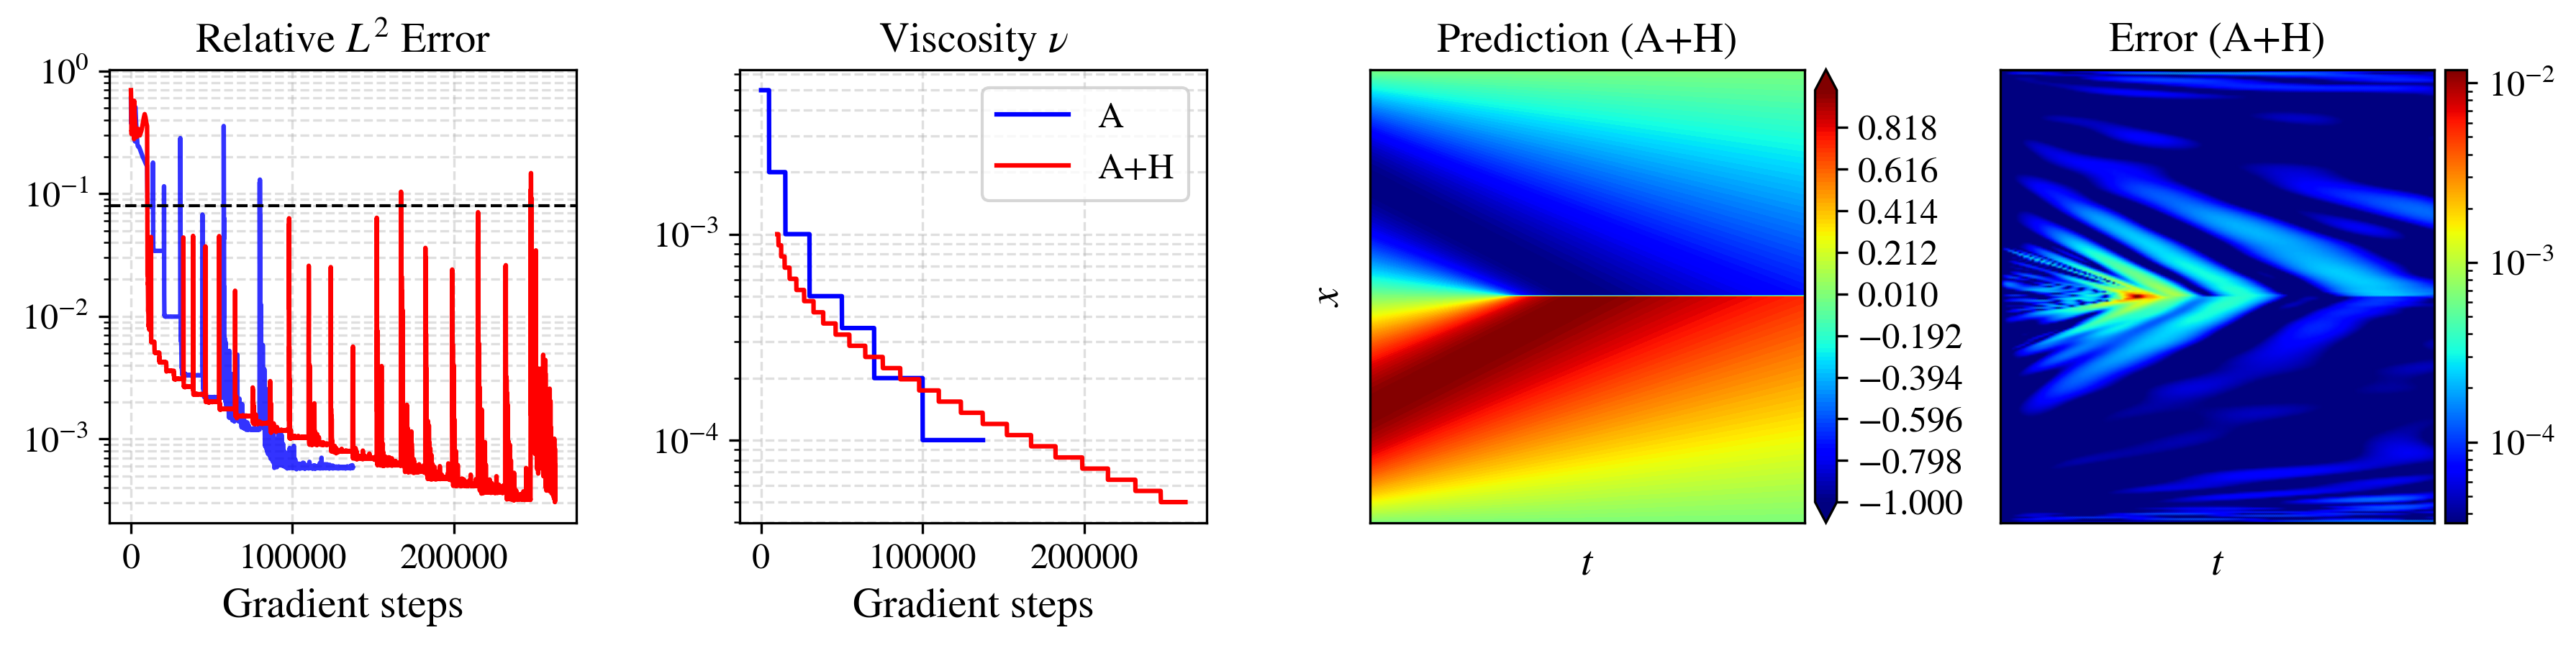

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import colors
from mpl_toolkits.axes_grid1 import make_axes_locatable

# ============================================================================
# 1. SETUP & STYLE
# ============================================================================
# === FONTSIZE CONFIGURATION ===
BASE_FONTSIZE = 14  # Change this value to adjust all fonts proportionally
TITLE_FONTSIZE = BASE_FONTSIZE
LABEL_FONTSIZE = BASE_FONTSIZE
LEGEND_FONTSIZE = BASE_FONTSIZE - 2
TICK_FONTSIZE = BASE_FONTSIZE - 2
COLORBAR_FONTSIZE = BASE_FONTSIZE - 2

mpl.rcParams['mathtext.fontset'] = 'stix'
mpl.rcParams['font.family'] = 'STIXGeneral'
mpl.rcParams['font.size'] = BASE_FONTSIZE
mpl.rcParams['figure.dpi'] = 300

# Define paths
path_case_a = '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/Burgers_Periodic_SinPiX/2025_12_04_1621_human_IB/burgers_pred_complete.npz'
path_case_ah = '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/Burgers_Periodic_SinPiX/2025_11_25_0148_wavelets_lower/viscosity_results_complete.npz'

# ============================================================================
# 2. LOAD DATA
# ============================================================================
print("Loading data...")

# --- Case A ---
data_a = np.load(path_case_a)
a_iter = data_a['iter_history']
a_error = data_a['error_history']

# --- Case A+H ---
data_ah = np.load(path_case_ah)
ah_iter = data_ah['iter_history']
ah_error = data_ah['error_history']
ah_viscosity = data_ah['viscosity_history']
ah_T = data_ah['T']
ah_X = data_ah['X']
ah_u_pred = data_ah['u_pred']
ah_u_exact = data_ah['u_exact']

# Compute pointwise error for Case A+H
ah_pointwise_error = np.abs(ah_u_exact - ah_u_pred)

# Align Case A+H Viscosity Iterations
ah_iter_visc = ah_iter[-len(ah_viscosity):]

# ============================================================================
# 3. RECONSTRUCT VISCOSITY FOR CASE A
# ============================================================================
continuation_schedule = [
    {'nu': 0.005, 'dwell': 5000},
    {'nu': 0.002, 'dwell': 10000},
    {'nu': 0.001, 'dwell': 15000},
    {'nu': 0.0005, 'dwell': 20000},
    {'nu': 0.00035, 'dwell': 20000},
    {'nu': 0.0002, 'dwell': 30000},
    {'nu': 0.0001, 'dwell': 80000},
]

# Create a full array where index = iteration number
total_scheduled_iters = sum(stage['dwell'] for stage in continuation_schedule)
max_iter = max(a_iter.max(), total_scheduled_iters) + 1
full_visc_schedule = np.zeros(int(max_iter))

current_idx = 0
for stage in continuation_schedule:
    end_idx = current_idx + stage['dwell']
    full_visc_schedule[current_idx:end_idx] = stage['nu']
    current_idx = end_idx

if current_idx < len(full_visc_schedule):
    full_visc_schedule[current_idx:] = continuation_schedule[-1]['nu']

# Map to actual saved iterations
a_visc_history = full_visc_schedule[a_iter.astype(int)]

print("Viscosity mapped and data ready.")

# ============================================================================
# 4. PLOTTING
# ============================================================================
color_a = 'blue'
color_ah = 'red'

fig = plt.figure(figsize=(12, 3))
gs = fig.add_gridspec(1, 4, wspace=0.35, top=0.85, bottom=0.15, left=0.05, right=0.96)

# --- COLUMN 1: RELATIVE ERROR ---
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(a_iter, a_error, color=color_a, linestyle='-', linewidth=1.5, label='A', alpha=0.8)
ax1.plot(ah_iter, ah_error, color=color_ah, linestyle='-', linewidth=1.5, label='A+H')
ax1.axhline(y=0.08, color='k', linestyle='--', linewidth=1, alpha=1)
ax1.set_yscale('log')
ax1.set_xlabel('Gradient steps', fontsize=LABEL_FONTSIZE)
ax1.set_title('Relative $L^2$ Error', fontsize=TITLE_FONTSIZE)
ax1.grid(True, which="both", ls="--", alpha=0.4)
ax1.tick_params(labelsize=TICK_FONTSIZE)

# --- COLUMN 2: VISCOSITY SCHEMES (LOG SCALE) ---
ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(a_iter, a_visc_history, color=color_a, linestyle='-', linewidth=1.5, label='A')
ax2.plot(ah_iter_visc, ah_viscosity, color=color_ah, linestyle='-', linewidth=1.5, label='A+H')
ax2.set_xlabel('Gradient steps', fontsize=LABEL_FONTSIZE)
ax2.set_title(r'Viscosity $\nu$', fontsize=TITLE_FONTSIZE)
ax2.legend( fontsize=LEGEND_FONTSIZE)
ax2.set_yscale('log')
ax2.grid(True, ls="--", alpha=0.4, which="both")
ax2.tick_params(labelsize=TICK_FONTSIZE)

# --- COLUMN 3: PREDICTION (Case A+H) ---
ax3 = fig.add_subplot(gs[0, 2])
levels_pred = np.linspace(ah_u_pred.min(), ah_u_pred.max(), 100)
contour3 = ax3.contourf(ah_T, ah_X, ah_u_pred, cmap='jet', levels=levels_pred, extend='both')
ax3.set_title('Prediction (A+H)', fontsize=TITLE_FONTSIZE)
ax3.set_xlabel('$t$', fontsize=LABEL_FONTSIZE)
ax3.set_ylabel('$x$', fontsize=LABEL_FONTSIZE)
ax3.set_xticks([])
ax3.set_yticks([])

# Slim Colorbar
divider3 = make_axes_locatable(ax3)
cax3 = divider3.append_axes("right", size="5%", pad=0.05)
cbar3 = fig.colorbar(contour3, cax=cax3)
cbar3.ax.tick_params(labelsize=COLORBAR_FONTSIZE)

# --- COLUMN 4: POINTWISE ERROR (REVERTED TO PCOLORMESH) ---
ax4 = fig.add_subplot(gs[0, 3])

# Safe log norm handling
err_safe = np.maximum(ah_pointwise_error, 1e-16)
norm_err = colors.LogNorm(vmin=np.median(err_safe), vmax=err_safe.max())

# Using pcolormesh + gouraud shading (Initial style)
mesh4 = ax4.pcolormesh(ah_T, ah_X, err_safe, cmap='jet', norm=norm_err, shading='gouraud')

ax4.set_title('Error (A+H)', fontsize=TITLE_FONTSIZE)
ax4.set_xlabel('$t$', fontsize=LABEL_FONTSIZE)
ax4.set_xticks([])
ax4.set_yticks([])

# Slim Colorbar
divider4 = make_axes_locatable(ax4)
cax4 = divider4.append_axes("right", size="5%", pad=0.05)
cbar4 = fig.colorbar(mesh4, cax=cax4)
cbar4.ax.tick_params(labelsize=COLORBAR_FONTSIZE)

# ============================================================================
# 5. SAVE
# ============================================================================
output_file = 'burgers_comparison_final_v3.png'
plt.savefig(output_file, dpi=300, bbox_inches='tight')
print(f"Figure saved as '{output_file}'")

plt.show()
# ============================================================================
# 6. METRIC EXTRACTION FROM RESIDUALS & HISTORY
# ============================================================================

def get_detailed_metrics(data_obj, name):
    # Extract History
    iters = data_obj['iter_history']
    errors = data_obj['error_history']
    
    # Identify state at minimum Relative L2 Error
    idx_min = np.argmin(errors)
    iter_at_min = iters[idx_min]
    err_at_min = errors[idx_min]
    loss_at_min = loss[idx_min]
    
    # Extract Residual Grid and compute metrics
    # res_grid is (N_t, N_x) or similar meshgrid shape
    res_grid = data_obj['pde_residual_grid']
    mse_res = np.mean(np.square(res_grid))
    max_res = np.abs(res_grid).max()
    
    # Extract Pointwise Error (Prediction vs Exact)
    u_p = data_obj['u_pred']
    u_e = data_obj['u_exact']
    pw_err = np.abs(u_e - u_p)
    
    return {
        'name': name,
        'iter_min': iter_at_min,
        'err_min': err_at_min,
        'loss_min': loss_at_min,
        'mse_res': mse_res,
        'max_res': max_res,
        'mean_pw': np.mean(pw_err),
        'max_pw': np.max(pw_err)
    }



In [12]:
# ============================================================================
# 6. RESIDUAL & ERROR METRIC EXTRACTION
# ============================================================================

def extract_case_metrics(data_obj, name):
    # 1. Extract Residual Data from 'pde_residual_grid'
    res_grid = data_obj['pde_residual_grid']
    mse_res = np.mean(np.square(res_grid))
    max_res = np.abs(res_grid).max()
    
    # 2. Extract Accuracy Metrics (Relative L2 Error)
    errors = data_obj['error_history']
    final_err = errors[-1]
    min_err = np.min(errors)
    
    # 3. Extract Pointwise Error (Spatial Difference)
    u_p = data_obj['u_pred']
    u_e = data_obj['u_exact']
    pw_err = np.abs(u_e - u_p)
    mean_pw = np.mean(pw_err)
    max_pw = np.max(pw_err)
    
    return {
        'name': name,
        'mse_res': mse_res,
        'max_res': max_res,
        'final_err': final_err,
        'min_err': min_err,
        'mean_pw': mean_pw,
        'max_pw': max_pw
    }

# Compute statistics for both cases
stats_a = extract_case_metrics(data_a, "Case A (ATHENA)")
stats_ah = extract_case_metrics(data_ah, "Case A+H (ATHENA+H)")

# ============================================================================
# 7. FINAL PERFORMANCE REPORT
# ============================================================================

print("\n" + "="*70)
print("BURGERS PDE RESIDUAL & ACCURACY REPORT")
print("="*70)

for s in [stats_a, stats_ah]:
    print(f"\n{s['name']}:")
    print(f"  --- PDE Residual Metrics ---")
    print(f"  Mean Squared Error (MSE): {s['mse_res']:.6e}")
    print(f"  Maximum Absolute Value:   {s['max_res']:.6e}")
    
    print(f"  --- Solution Accuracy ---")
    print(f"  Final Relative L2:        {s['final_err']:.6e}")
    print(f"  Minimum Relative L2:      {s['min_err']:.6e}")
    print(f"  Mean Pointwise Error:     {s['mean_pw']:.6e}")
    print(f"  Max Pointwise Error:      {s['max_pw']:.6e}")

print("\n" + "="*70)


BURGERS PDE RESIDUAL & ACCURACY REPORT

Case A (ATHENA):
  --- PDE Residual Metrics ---
  Mean Squared Error (MSE): 6.945362e-07
  Maximum Absolute Value:   1.360232e-01
  --- Solution Accuracy ---
  Final Relative L2:        5.820131e-04
  Minimum Relative L2:      5.653585e-04
  Mean Pointwise Error:     1.027806e-04
  Max Pointwise Error:      1.990337e-02

Case A+H (ATHENA+H):
  --- PDE Residual Metrics ---
  Mean Squared Error (MSE): 1.016252e-05
  Maximum Absolute Value:   4.080659e-01
  --- Solution Accuracy ---
  Final Relative L2:        3.225417e-04
  Minimum Relative L2:      3.052663e-04
  Mean Pointwise Error:     6.890055e-05
  Max Pointwise Error:      1.185010e-02

